This notebook is the continuation of the exploitation of CNN's, in the first notebook, i have trained a Convolutional Neural Network on the famous MNIST dataset wich is about recognition of white digits on a black backgroung so everything is on a grayscale, wich is easyier. Now that the model is trained and that the weights of the network are saved in mnist_cnn.pt, i can use the previously trained model on new imported data: this notebook take the path of the images taken from your smartphone on your computer and process them so it can correspond to a MNIST image and make a prediction on what it is. Try it yourself!

1. IMPORTATION

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

import torch
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image, ImageOps, ImageChops, ImageFilter
from scipy import ndimage

torch.manual_seed(0)
np.random.seed(0)
device = "cpu"

# Mêmes valeurs de normalisation qu'à l'entraînement (MNIST_PyTorch.ipynb)
MEAN, STD = 0.1307, 0.3081

2. IMPORTATION OF THE MODEL

In [2]:
from model import CNN

model = CNN().to(device)
model.load_state_dict(torch.load("mnist_cnn.pt", map_location=device))
model.eval()   # désactive le dropout pour des prédictions stables

CNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
  (dropout): Dropout(p=0.3, inplace=False)
)

3. IMAGE RECOGNITION SCRIPT

In [3]:
def preprocess(image, invert=True, seuil=110, debug=False):
    # Fond transparent -> fond blanc
    if image.mode in ("RGBA", "LA"):
        fond = Image.new("RGBA", image.size, (255, 255, 255, 255))
        image = Image.alpha_composite(fond, image.convert("RGBA"))

    image = ImageOps.exif_transpose(image)          # corrige la rotation des photos de téléphone
    img = image.convert("L")
    if invert:
        img = ImageOps.invert(img)                  # chiffre clair sur fond sombre
    img = ImageOps.autocontrast(img, cutoff=2)
    img.thumbnail((400, 400))                       # réduit la photo (plus rapide, moins de bruit)
    etapes = [("contraste", img.copy())]

    # Masque binaire : ce qui est nettement plus clair que le fond
    masque = img.point(lambda p: 255 if p > seuil else 0)
    etapes.append(("masque brut", masque.copy()))

    # On écarte tout ce qui touche le bord de la photo (bords, ombres)
    lab, n = ndimage.label(np.asarray(masque) > 0)
    if n == 0:
        raise ValueError("Rien de détecté : baisse `seuil`.")
    bords = set(np.unique(np.concatenate([lab[0], lab[-1], lab[:, 0], lab[:, -1]])))
    aires = ndimage.sum(np.ones_like(lab), lab, index=range(1, n + 1))
    gardes = [i for i in range(1, n + 1) if i not in bords]
    if not gardes:
        raise ValueError("Le chiffre touche le bord de la photo : laisse une marge autour.")
    plus_grande = max(aires[i - 1] for i in gardes)
    gardes = [i for i in gardes if aires[i - 1] >= 0.2 * plus_grande]
    masque = Image.fromarray((np.isin(lab, gardes) * 255).astype(np.uint8))
    etapes.append(("chiffre isolé", masque.copy()))

    # Recadrage sur le chiffre, puis réduction pour que la suite soit rapide
    masque = masque.crop(masque.getbbox())
    masque.thumbnail((100, 100))

    # Trait épaissi proportionnellement à la taille du chiffre (comme MNIST)
    k = 2 * max(1, int(0.04 * max(masque.size))) + 1
    masque = ImageOps.expand(masque, border=k, fill=0)
    masque = masque.filter(ImageFilter.MaxFilter(k))
    masque = masque.crop(masque.getbbox())
    etapes.append(("trait épaissi", masque.copy()))

    # 20 px de côté max, proportions conservées, centré dans 28x28
    w, h = masque.size
    echelle = 20 / max(w, h)
    taille = (max(1, round(w * echelle)), max(1, round(h * echelle)))
    masque = masque.resize(taille, Image.LANCZOS)
    canvas = Image.new("L", (28, 28), 0)
    canvas.paste(masque, ((28 - taille[0]) // 2, (28 - taille[1]) // 2))

    # Recentrage par centre de masse, comme dans MNIST
    a = np.asarray(canvas, dtype=np.float64)
    ys, xs = np.indices(a.shape)
    cy = (ys * a).sum() / a.sum()
    cx = (xs * a).sum() / a.sum()
    canvas = ImageChops.offset(canvas, round(13.5 - cx), round(13.5 - cy))
    etapes.append(("28×28 final", canvas))

    if debug:
        fig, axes = plt.subplots(1, len(etapes), figsize=(3 * len(etapes), 3))
        for ax, (titre, im) in zip(axes, etapes):
            ax.imshow(im, cmap="gray")
            ax.set_title(titre)
            ax.axis("off")
        plt.show()

    # Mêmes transformations qu'à l'entraînement, same transformation to keep the MNIST norm
    tenseur = transforms.ToTensor()(canvas)
    tenseur = transforms.Normalize((MEAN,), (STD,))(tenseur)
    return tenseur.unsqueeze(0), canvas             # (1, 1, 28, 28)

4. PREDICTION FUNCTION

In [7]:
def predict(chemin_image, invert=True, seuil=110, debug=True):
    x, apercu = preprocess(Image.open(chemin_image), invert=invert, seuil=seuil, debug=debug)
    with torch.no_grad():
        probas = F.softmax(model(x.to(device)), dim=1)[0]

    top3 = torch.topk(probas, 3)
    chiffre = top3.indices[0].item()

    if not debug:
        plt.imshow(apercu, cmap="gray")
        plt.title(f"Prédiction : {chiffre} ({top3.values[0].item():.1%})")
        plt.axis("off")
        plt.show()

    print(f"Prédiction : {chiffre} ({top3.values[0].item():.1%})")
    for p, i in zip(top3.values, top3.indices):
        print(f"  {i.item()} : {p.item():.1%}")

5. FINAL RESULT: drop your photo(s) in the `photos` folder, then run this cell

Image used : Exemple_0.jpg


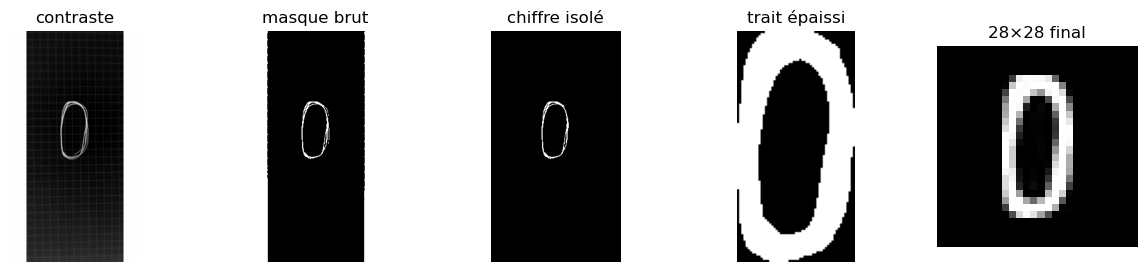

Prédiction : 0 (100.0%)
  0 : 100.0%
  8 : 0.0%
  2 : 0.0%


In [ ]:
dossier = Path("../Photos")
extensions = {".jpg", ".jpeg", ".png", ".webp"}
images = [p for p in dossier.iterdir() if p.suffix.lower() in extensions]

if not images:
    raise FileNotFoundError(f"Aucune image trouvée dans '{dossier.resolve()}'. Dépose une photo (.jpg, .png, .webp) dedans.")

chemin = max(images, key=lambda p: p.stat().st_mtime)   # the most recent
print(f"Image used : {chemin.name}")
predict(chemin)